# Bab 15 — Deep Learning on Unseen Data: Federated Learning
**Acuan:** Trask, *Grokking Deep Learning*, Bab 15 (hlm. 281–291).

Tujuan: melatih model pada beberapa client, menggabungkan pembaruan, memahami kebocoran gradien, dan membedakan secure aggregation dari enkripsi homomorfik. Data spam mini dibuat sendiri dan seluruh client disimulasikan dalam satu proses; ini tidak menerapkan jaringan federasi atau kriptografi produksi.

## Model berpindah ke data
Server mengirim bobot global; client melakukan langkah training lokal; server menggabungkan bobot client dengan rata-rata berbobot jumlah contoh (FedAvg). Tujuan global adalah jumlah loss lokal berbobot ukuran dataset. Data non-IID, jumlah langkah lokal, client yang absen, dan ukuran dataset yang tidak sama dapat mengubah konvergensi. Data yang tetap lokal mengurangi kebutuhan sentralisasi, tetapi pembaruan model juga dapat membocorkan informasi.

Loss awal/akhir: 0.6931471805579453 0.05813470829480768
Bobot: {'free': np.float64(2.052), 'prize': np.float64(2.652), 'meeting': np.float64(-2.145), 'project': np.float64(-2.15)}


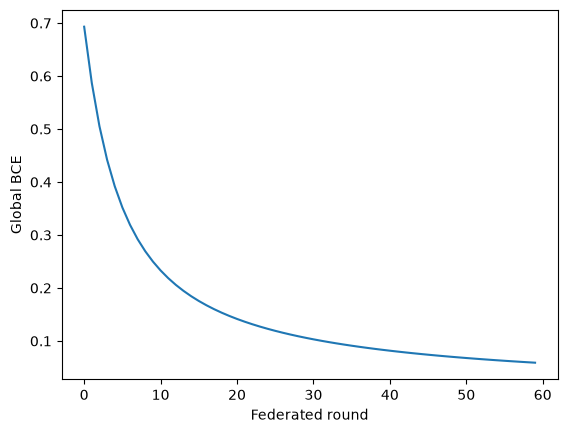

In [1]:
import numpy as np
import matplotlib.pyplot as plt
vocab=['free','prize','meeting','project']
# Bag-of-words: contoh sintetis, bukan email pengguna.
clients=[(np.array([[1.,1.,0.,0.],[0.,0.,1.,1.],[1.,0.,0.,0.]]),np.array([1.,0.,1.])),
         (np.array([[0.,1.,0.,0.],[0.,0.,1.,0.]]),np.array([1.,0.])),
         (np.array([[1.,1.,0.,0.],[0.,0.,0.,1.],[0.,0.,1.,1.],[0.,1.,0.,0.]]),np.array([1.,0.,0.,1.]))]
sigmoid=lambda z:1/(1+np.exp(-np.clip(z,-30,30)))
def local_train(weights,X,y,steps=3,lr=.3):
    w=weights.copy()
    for _ in range(steps): w-=lr*(X.T@(sigmoid(X@w)-y)/len(y))
    return w
def global_loss(w):
    X=np.vstack([x for x,y in clients]); y=np.concatenate([y for x,y in clients])
    p=sigmoid(X@w)
    return -np.mean(y*np.log(p+1e-12)+(1-y)*np.log(1-p+1e-12))
w=np.zeros(4); history=[]
for round_id in range(60):
    history.append(global_loss(w))
    updates=[local_train(w,X,y) for X,y in clients]
    sizes=np.array([len(y) for X,y in clients])
    w=np.average(updates,axis=0,weights=sizes)
print('Loss awal/akhir:',history[0],global_loss(w))
print('Bobot:',dict(zip(vocab,w.round(3))))
plt.plot(history); plt.xlabel('Federated round'); plt.ylabel('Global BCE'); plt.show()
assert global_loss(w)<history[0]

## Mengapa update bisa membocorkan data?
Untuk satu contoh pada model logistic dengan bobot nol, gradien adalah (0,5−y)x. Pada label spam y=1, koordinat nonzero pada gradien langsung mengungkap token yang muncul. Serangan ini adalah ilustrasi aljabar pada data sintetis sendiri; agregasi banyak contoh dan banyak langkah mengubah kemudahan rekonstruksi, tetapi tidak memberi jaminan privasi dengan sendirinya.

In [2]:
toy_x=np.array([1.,1.,0.,0.]); toy_y=1.
gradient=(.5-toy_y)*toy_x
recovered=gradient/(.5-toy_y)
print('Gradient:',gradient,'recovered presence:',recovered)
assert np.allclose(recovered,toy_x)

Gradient: [-0.5 -0.5 -0.  -0. ] recovered presence: [1. 1. 0. 0.]


## Secure aggregation: ilustrasi pembatalan mask
Client dapat menambah mask berpasangan sehingga mask saling menghapus pada jumlah akhir. Server melihat jumlah update, bukan update individual dalam model ancaman dan protokol yang sesuai. Contoh berikut mengilustrasikan identitas penjumlahannya saja: semua mask diketahui satu proses, tanpa pertukaran kunci, penanganan dropout client, atau perlindungan dari kolusi. Enkripsi homomorfik berbeda: operasi tertentu dilakukan pada ciphertext dan hasil didekripsi oleh pemegang kunci; tidak diimplementasikan oleh mask sederhana ini.

In [3]:
rng=np.random.default_rng(15)
updates=np.array([[.1,.2],[-.2,.3],[.4,-.1]])
mask01=rng.normal(size=2); mask02=rng.normal(size=2); mask12=rng.normal(size=2)
masked=np.array([updates[0]+mask01+mask02,
                 updates[1]-mask01+mask12,
                 updates[2]-mask02-mask12])
print('Agregat bermask:',masked.sum(0),'agregat asli:',updates.sum(0))
assert np.allclose(masked.sum(0),updates.sum(0))

Agregat bermask: [0.3 0.4] agregat asli: [0.3 0.4]


## Ringkasan dan keterbatasan
FedAvg menggabungkan hasil training lokal; rata-rata berbobot penting saat ukuran client berbeda. Federasi sendiri bukan jaminan privasi. Secure aggregation melindungi visibilitas update individual pada asumsi tertentu, sementara differential privacy dapat membatasi pengaruh individu dengan biaya utilitas. Enkripsi homomorfik menyediakan operasi pada data terenkripsi dengan biaya komputasi dan pengelolaan kunci. Penerapan nyata memerlukan protokol teruji serta evaluasi model ancaman; simulasi ini hanya menjelaskan mekanismenya.